# Two-Indicator Scalping Strategy for NIFTY 50 (VWAP + RSI)
**AstraQuant X-2026 | Problem 15**

Run the cells top to bottom. Data: 5-minute OHLCV bars. Pre-loaded with current real NIFTY 50 5-minute intraday data in `data/`, with automated live fallback via `yfinance`.

**Idea:** VWAP gives the trend direction, RSI(7) times the entry. Fixed stop-loss and target, realistic Indian intraday costs, and walk-forward validation (tune on train, judge on test).

## 1. Setup and config
All tunable parameters live in `CFG`. Local CSV data in `data/` is loaded by default, and `USE_YFINANCE = True` enables live data refresh.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CFG = dict(
    rsi_len=7,
    rsi_low=35,            # long trigger: RSI crosses UP through this
    rsi_high=65,           # short trigger: RSI crosses DOWN through this
    stop_pct=0.0030,       # 0.30% stop-loss
    target_pct=0.0060,     # 0.60% target  -> risk:reward = 1:2
    max_hold_bars=12,      # time stop (12 x 5min = 1 hour)
    no_entry_before="09:30",  # skip the noisy opening 15 minutes
    no_entry_after="14:45",
    max_trades_per_day=3,     # per stock
    daily_loss_limit=1500,    # Rs per stock per day, stop trading after this
    square_off="15:15",
    capital_per_trade=100_000,   # Rs per trade
    initial_capital=1_000_000,   # for Sharpe / drawdown %
    slippage_pct=0.0001,   # 0.01% per side
)

# Choose universe: NIFTY 50 top liquid constituents or NIFTY index/ETF
# Top Nifty 50 heavyweight sample:
NIFTY_SAMPLE = ["RELIANCE", "HDFCBANK", "ICICIBANK", "INFY", "TCS", "SBIN"]
# To trade NIFTY 50 index/ETF instead, uncomment either line:
# NIFTY_SAMPLE = ["NIFTYBEES"]  # Tradable Nifty 50 ETF with full traded volume
# NIFTY_SAMPLE = ["NIFTY50"]   # Direct Nifty 50 Index (^NSEI)

USE_YFINANCE = True
DATA_DIR = Path("data")
OUT_DIR = Path("output"); OUT_DIR.mkdir(exist_ok=True)

## 2. Data loading
Loads current 5-minute OHLCV bars (`datetime,open,high,low,close,volume`) from local CSVs in `data/`, with automated live download via `yfinance` for up-to-date data.

In [2]:
def load_csv(sym):
    csv_path = DATA_DIR / f"{sym}.csv"
    df = pd.read_csv(csv_path, parse_dates=["datetime"], index_col="datetime")
    return df[["open", "high", "low", "close", "volume"]].sort_index()


def load_yf(sym):
    import yfinance as yf
    # Resolve Yahoo Finance ticker symbol for NIFTY 50 or Indian equities
    if sym in ["NIFTY50", "NIFTY_50", "NIFTY", "^NSEI"]:
        ticker = "^NSEI"
    elif sym.startswith("^") or sym.endswith(".NS"):
        ticker = sym
    else:
        ticker = f"{sym}.NS"
    df = yf.download(ticker, period="60d", interval="5m", progress=False)
    # Flatten MultiIndex columns if returned by newer yfinance versions
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [c[0].lower() for c in df.columns]
    else:
        df.columns = [c.lower() for c in df.columns]
    if df.index.tz is not None:
        df.index = df.index.tz_convert("Asia/Kolkata").tz_localize(None)
    for col in ["open", "high", "low", "close", "volume"]:
        if col not in df.columns:
            df[col] = 0.0
    return df[["open", "high", "low", "close", "volume"]].sort_index()


def synthetic(sym, days=40, seed=0):
    """Fallback generator in case both local CSV and yfinance are unavailable."""
    rng = np.random.default_rng(abs(hash(sym)) % (2**32) + seed)
    price, rows = 1000 * (1 + rng.random()), []
    for d in pd.bdate_range("2026-09-01", periods=days):
        times = pd.date_range(d + pd.Timedelta("09:15:00"), periods=75, freq="5min")
        drift = rng.normal(0, 0.0002)
        for t in times:
            o = price
            c = o * (1 + drift + rng.normal(0, 0.0012))
            h = max(o, c) * (1 + abs(rng.normal(0, 0.0004)))
            l = min(o, c) * (1 - abs(rng.normal(0, 0.0004)))
            rows.append((t, o, h, l, c, int(rng.integers(5e4, 3e5))))
            price = c
    return pd.DataFrame(rows, columns=["datetime", "open", "high", "low", "close", "volume"]).set_index("datetime")


def get_data(sym):
    # 1. First priority: Load from local CSV (current actual 5-min data)
    csv_path = DATA_DIR / f"{sym}.csv"
    if csv_path.exists():
        print(f"Loading {sym} from {csv_path}...")
        return load_csv(sym)
    # 2. Second priority: Fetch live via yfinance if enabled
    if USE_YFINANCE:
        try:
            print(f"Fetching current live data for {sym} via yfinance...")
            return load_yf(sym)
        except Exception as e:
            print(f"Warning: yfinance fetch failed for {sym}: {e}")
    # 3. Fallback: Synthetic offline testing data
    print(f"Warning: Using synthetic fallback data for {sym}.")
    return synthetic(sym)

## 3. Indicators
1. **VWAP** (resets daily) = trend filter (supports volume-weighted calculation for stocks/ETFs and TWAP fallback for indices without volume feed)
2. **RSI(7)** = entry trigger

In [3]:
def add_indicators(df, rsi_len):
    df = df.copy()
    df["date"] = df.index.date
    # --- Indicator 1: intraday VWAP, resets every day ---
    tp = (df.high + df.low + df.close) / 3
    if (df.volume > 0).any():
        pv = (tp * df.volume).groupby(df["date"]).cumsum()
        vv = df.volume.groupby(df["date"]).cumsum()
        df["vwap"] = np.where(vv > 0, pv / vv, tp.groupby(df["date"]).expanding().mean().values)
    else:
        # Fallback for indices without volume (e.g. ^NSEI): time-weighted average price (TWAP)
        df["vwap"] = tp.groupby(df["date"]).expanding().mean()
    # --- Indicator 2: RSI (Wilder smoothing) ---
    delta = df.close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / rsi_len, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / rsi_len, adjust=False).mean()
    df["rsi"] = 100 - 100 / (1 + gain / loss.replace(0, np.nan))
    return df

## 4. Signals
Computed on bar close and executed on the **next bar open** (no look-ahead).

In [4]:
def add_signals(df, c):
    prev = df.rsi.shift(1)
    long_ = (df.close > df.vwap) & (prev < c["rsi_low"]) & (df.rsi >= c["rsi_low"])
    short_ = (df.close < df.vwap) & (prev > c["rsi_high"]) & (df.rsi <= c["rsi_high"])
    df["signal"] = np.where(long_, 1, np.where(short_, -1, 0))
    return df

## 5. Transaction costs
Brokerage, STT, exchange fee, SEBI fee, stamp duty, GST (approximate rates, verify with your broker).

In [5]:
def charges(buy_val, sell_val):
    brokerage = min(20, 0.0003 * buy_val) + min(20, 0.0003 * sell_val)  # 0.03% or Rs20/order
    stt = 0.00025 * sell_val                    # STT on sell side (intraday)
    exch = 0.0000297 * (buy_val + sell_val)     # NSE transaction charge
    sebi = 0.000001 * (buy_val + sell_val)
    stamp = 0.00003 * buy_val                   # buy side only
    gst = 0.18 * (brokerage + exch + sebi)
    return brokerage + stt + exch + sebi + stamp + gst

## 6. Backtest engine
One position per stock, stop-loss/target/time exits, square-off 15:15, daily trade and loss limits.

In [6]:
def backtest(df, sym, c):
    trades = []
    for day, g in df.groupby("date"):
        o, h, l, cl = g.open.values, g.high.values, g.low.values, g.close.values
        sig, times, idx = g.signal.values, g.index.strftime("%H:%M").values, g.index
        n, j = len(g), 0
        day_trades, day_pnl = 0, 0.0
        while j < n - 1:
            if (sig[j] == 0 or times[j] > c["no_entry_after"] or times[j] < c["no_entry_before"]
                    or day_trades >= c["max_trades_per_day"] or day_pnl <= -c["daily_loss_limit"]):
                j += 1
                continue
            side = int(sig[j])
            entry_i = j + 1
            entry = o[entry_i] * (1 + c["slippage_pct"] * side)
            sl = entry * (1 - side * c["stop_pct"])
            tp = entry * (1 + side * c["target_pct"])
            exit_px, reason, k = None, None, entry_i
            for k in range(entry_i, n):
                hit_sl = l[k] <= sl if side == 1 else h[k] >= sl
                hit_tp = h[k] >= tp if side == 1 else l[k] <= tp
                if hit_sl:                       # conservative: SL wins if both hit
                    exit_px, reason = sl, "SL"; break
                if hit_tp:
                    exit_px, reason = tp, "TP"; break
                if times[k] >= c["square_off"] or k == n - 1:
                    exit_px, reason = cl[k], "EOD"; break
                if k - entry_i + 1 >= c["max_hold_bars"]:
                    exit_px, reason = cl[k], "TIME"; break
            exit_px *= (1 - c["slippage_pct"] * side)
            qty = max(int(c["capital_per_trade"] / entry), 1)
            gross = side * (exit_px - entry) * qty
            buy_val = (entry if side == 1 else exit_px) * qty
            sell_val = (exit_px if side == 1 else entry) * qty
            cost = charges(buy_val, sell_val)
            trades.append(dict(symbol=sym, date=day, entry_time=idx[entry_i], exit_time=idx[k],
                               side="LONG" if side == 1 else "SHORT", entry=entry, exit=exit_px,
                               qty=qty, gross_pnl=gross, costs=cost, net_pnl=gross - cost, reason=reason))
            day_trades += 1
            day_pnl += gross - cost
            j = k + 1
    return pd.DataFrame(trades)

## 7. Performance metrics
Net P&L, win rate, risk-reward, profit factor, Sharpe ratio, max drawdown.

In [7]:
def metrics(tr, c):
    if tr.empty:
        return {"trades": 0}
    wins, losses = tr[tr.net_pnl > 0], tr[tr.net_pnl <= 0]
    daily = tr.groupby("date").net_pnl.sum()
    daily_ret = daily / c["initial_capital"]
    sharpe = daily_ret.mean() / daily_ret.std() * np.sqrt(252) if daily_ret.std() > 0 else np.nan
    eq = tr.sort_values("exit_time").net_pnl.cumsum()
    dd = eq - eq.cummax().clip(lower=0)
    avg_w = wins.net_pnl.mean() if len(wins) else 0
    avg_l = abs(losses.net_pnl.mean()) if len(losses) else np.nan
    return {
        "trades": len(tr),
        "gross_pnl": round(tr.gross_pnl.sum(), 2),
        "total_costs": round(tr.costs.sum(), 2),
        "net_pnl": round(tr.net_pnl.sum(), 2),
        "win_rate_%": round(100 * len(wins) / len(tr), 2),
        "avg_win": round(avg_w, 2),
        "avg_loss": round(-avg_l, 2) if avg_l == avg_l else np.nan,
        "risk_reward": round(avg_w / avg_l, 2) if avg_l and avg_l == avg_l else np.nan,
        "profit_factor": round(wins.net_pnl.sum() / abs(losses.net_pnl.sum()), 2) if len(losses) and losses.net_pnl.sum() else np.nan,
        "sharpe": round(sharpe, 2),
        "max_drawdown_Rs": round(dd.min(), 2),
        "max_drawdown_%": round(100 * dd.min() / c["initial_capital"], 2),
    }

## 8. Charts
Signal chart (price + VWAP + RSI with entries/exits) and equity/drawdown curve.

In [8]:
def plot_signals(df, tr, sym, day, path):
    g = df[df.date == day]
    t = tr[(tr.symbol == sym) & (tr.date == day)]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    a1.plot(g.index, g.close, label="Close", lw=1.2)
    a1.plot(g.index, g.vwap, label="VWAP", lw=1.2, ls="--")
    for _, r in t.iterrows():
        up = r.side == "LONG"
        a1.scatter(r.entry_time, r.entry, marker="^" if up else "v", c="green" if up else "red", s=110, zorder=5)
        a1.scatter(r.exit_time, r.exit, marker="x", c="black", s=70, zorder=5)
    a1.set_title(f"{sym} {day}  |  ^ long entry, v short entry, x exit"); a1.legend()
    a2.plot(g.index, g.rsi, c="purple"); a2.axhline(CFG["rsi_low"], c="g", ls=":"); a2.axhline(CFG["rsi_high"], c="r", ls=":")
    a2.set_ylabel("RSI(7)")
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()


def plot_equity(tr, path):
    if tr.empty:
        print("No trades to plot equity curve.")
        return
    t = tr.sort_values("exit_time")
    eq = t.net_pnl.cumsum().values
    dd = eq - np.maximum.accumulate(np.maximum(eq, 0))
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    a1.plot(eq); a1.set_title("Cumulative net P&L (Rs) after costs")
    a2.fill_between(range(len(dd)), dd, color="red", alpha=.4); a2.set_title("Drawdown (Rs)")
    a2.set_xlabel("Trade #")
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()

## 9. Walk-forward helpers
Parameter grid plus helper functions to run the strategy on a set of days.

In [9]:
GRID = dict(rsi_len=[5, 7, 9], rsi_low=[25, 30, 35, 40], stop_pct=[0.002, 0.003, 0.004], rr=[1.5, 2.0, 3.0])


def run_all(raw, cfg, day_filter):
    out = []
    for sym, r in raw.items():
        df = add_signals(add_indicators(r, cfg["rsi_len"]), cfg)
        df = df[df.date.isin(day_filter)]
        out.append(backtest(df, sym, cfg))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()


def make_cfg(rsi_len, rsi_low, stop_pct, rr):
    return {**CFG, "rsi_len": rsi_len, "rsi_low": rsi_low, "rsi_high": 100 - rsi_low,
            "stop_pct": stop_pct, "target_pct": stop_pct * rr}

## 10. Load data and split train/test
First 60% of days = TRAIN (tuning). Last 40% = TEST (never seen).

In [10]:
raw = {s_: get_data(s_) for s_ in NIFTY_SAMPLE}
days = sorted({d for r in raw.values() for d in r.index.date})
cut = int(len(days) * 0.6)
train_days, test_days = set(days[:cut]), set(days[cut:])
print(f"Total unique trading days: {len(days)}")
print(f"Train days: {len(train_days)}   Test days: {len(test_days)}")

Loading RELIANCE from data\RELIANCE.csv...
Loading HDFCBANK from data\HDFCBANK.csv...
Loading ICICIBANK from data\ICICIBANK.csv...
Loading INFY from data\INFY.csv...
Loading TCS from data\TCS.csv...
Loading SBIN from data\SBIN.csv...
Total unique trading days: 60
Train days: 36   Test days: 24


## 11. Grid search on TRAIN only

In [11]:
import itertools
rows = []
min_trades_req = 15 if len(NIFTY_SAMPLE) <= 2 else 30
for combo in itertools.product(*GRID.values()):
    p = dict(zip(GRID, combo))
    m = metrics(run_all(raw, make_cfg(**p), train_days), CFG)
    if m.get("trades", 0) >= min_trades_req:
        rows.append({**p, **m})
if not rows:
    for combo in itertools.product(*GRID.values()):
        p = dict(zip(GRID, combo))
        m = metrics(run_all(raw, make_cfg(**p), train_days), CFG)
        if m.get("trades", 0) > 0:
            rows.append({**p, **m})
grid = pd.DataFrame(rows).sort_values("net_pnl", ascending=False)
grid.to_csv(OUT_DIR / "grid_search_train.csv", index=False)
best = grid.iloc[0][list(GRID)].to_dict()
best["rsi_len"], best["rsi_low"] = int(best["rsi_len"]), int(best["rsi_low"])
print("Best params on TRAIN:", best)
grid.head(10)

Best params on TRAIN: {'rsi_len': 9, 'rsi_low': 25, 'stop_pct': 0.002, 'rr': 1.5}


,rsi_len,rsi_low,stop_pct,rr,trades,gross_pnl,total_costs,net_pnl,win_rate_%,avg_win,avg_loss,risk_reward,profit_factor,sharpe,max_drawdown_Rs,max_drawdown_%
72,9,25,0.002,1.5,52,372.78,4273.79,-3901.01,46.15,164.93,-280.69,0.59,0.50,-7.42,-3901.01,-0.39
80,9,25,0.004,3.0,50,74.68,4109.90,-4035.22,36.00,362.31,-329.90,1.10,0.62,-3.80,-6636.71,-0.66
73,9,25,0.002,2.0,52,-295.22,4273.56,-4568.78,40.38,187.76,-274.57,0.68,0.46,-8.42,-4568.78,-0.46
77,9,25,0.003,3.0,51,-883.21,4191.90,-5075.11,35.29,305.64,-320.50,0.95,0.52,-5.78,-6577.31,-0.66
41,7,25,0.003,3.0,81,1519.94,6658.35,-5138.41,38.27,301.21,-289.52,1.04,0.65,-4.14,-6264.32,-0.63
79,9,25,0.004,2.0,50,-1254.92,4109.74,-5364.66,36.00,288.45,-329.90,0.87,0.49,-5.69,-6724.11,-0.67
74,9,25,0.002,3.0,52,-1146.14,4273.64,-5419.78,34.62,207.10,-269.05,0.77,0.41,-8.40,-5537.95,-0.55
75,9,25,0.003,1.5,51,-1452.92,4191.53,-5644.46,39.22,207.73,-316.10,0.66,0.42,-8.42,-6254.77,-0.63
82,9,30,0.002,2.0,96,1894.73,7891.19,-5996.46,38.54,238.07,-250.93,0.95,0.59,-6.44,-5996.46,-0.60
38,7,25,0.002,3.0,81,549.85,6658.10,-6108.25,35.80,245.65,-254.46,0.97,0.54,-6.37,-6521.85,-0.65


## 12. In-sample vs out-of-sample results
Quote the **out-of-sample** column in your presentation.

In [12]:
bcfg = make_cfg(**best)
tr_train = run_all(raw, bcfg, train_days)
tr_test = run_all(raw, bcfg, test_days)
pd.DataFrame({"IN-SAMPLE (train)": metrics(tr_train, CFG),
              "OUT-OF-SAMPLE (test)": metrics(tr_test, CFG)})

,IN-SAMPLE (train),OUT-OF-SAMPLE (test)
trades,52.00,48.00
gross_pnl,372.78,-862.39
total_costs,4273.79,3946.53
net_pnl,-3901.01,-4808.92
win_rate_%,46.15,37.50
avg_win,164.93,205.95
avg_loss,-280.69,-283.87
risk_reward,0.59,0.73
profit_factor,0.50,0.44
sharpe,-7.42,-10.06


## 13. Per-stock results (TEST)

In [13]:
per_stock = pd.DataFrame({s_: metrics(tr_test[tr_test.symbol == s_], CFG) for s_ in NIFTY_SAMPLE}).T
per_stock[["trades", "net_pnl", "win_rate_%", "risk_reward", "sharpe", "max_drawdown_%"]]

,trades,net_pnl,win_rate_%,risk_reward,sharpe,max_drawdown_%
RELIANCE,7.0,-52.05,57.14,0.71,-0.44,-0.04
HDFCBANK,9.0,-1130.87,33.33,0.71,-9.92,-0.11
ICICIBANK,6.0,-256.85,50.00,0.71,-2.22,-0.09
INFY,12.0,-1003.65,41.67,0.71,-5.51,-0.14
TCS,6.0,-1241.73,16.67,0.71,-16.22,-0.14
SBIN,8.0,-1123.78,25.00,0.81,-10.08,-0.13


## 14. Charts (TEST period)

reason
SL      29
TP      18
TIME     1
Name: count, dtype: int64


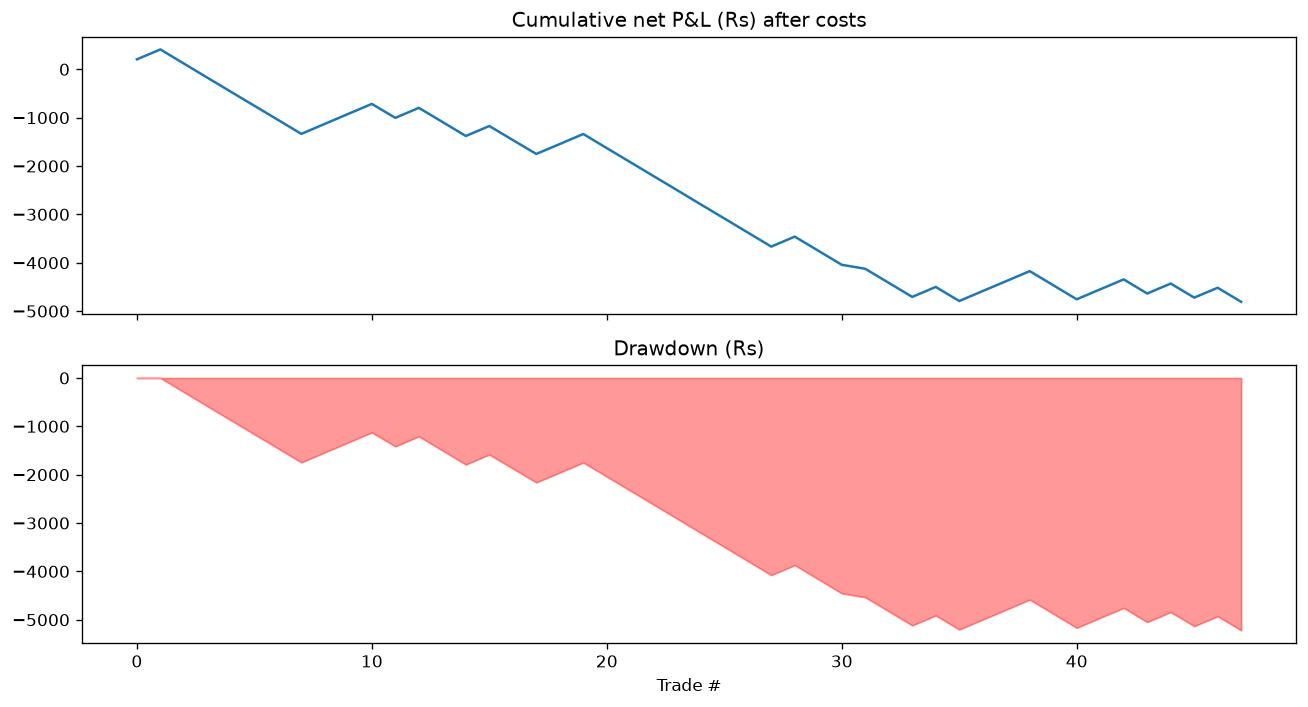

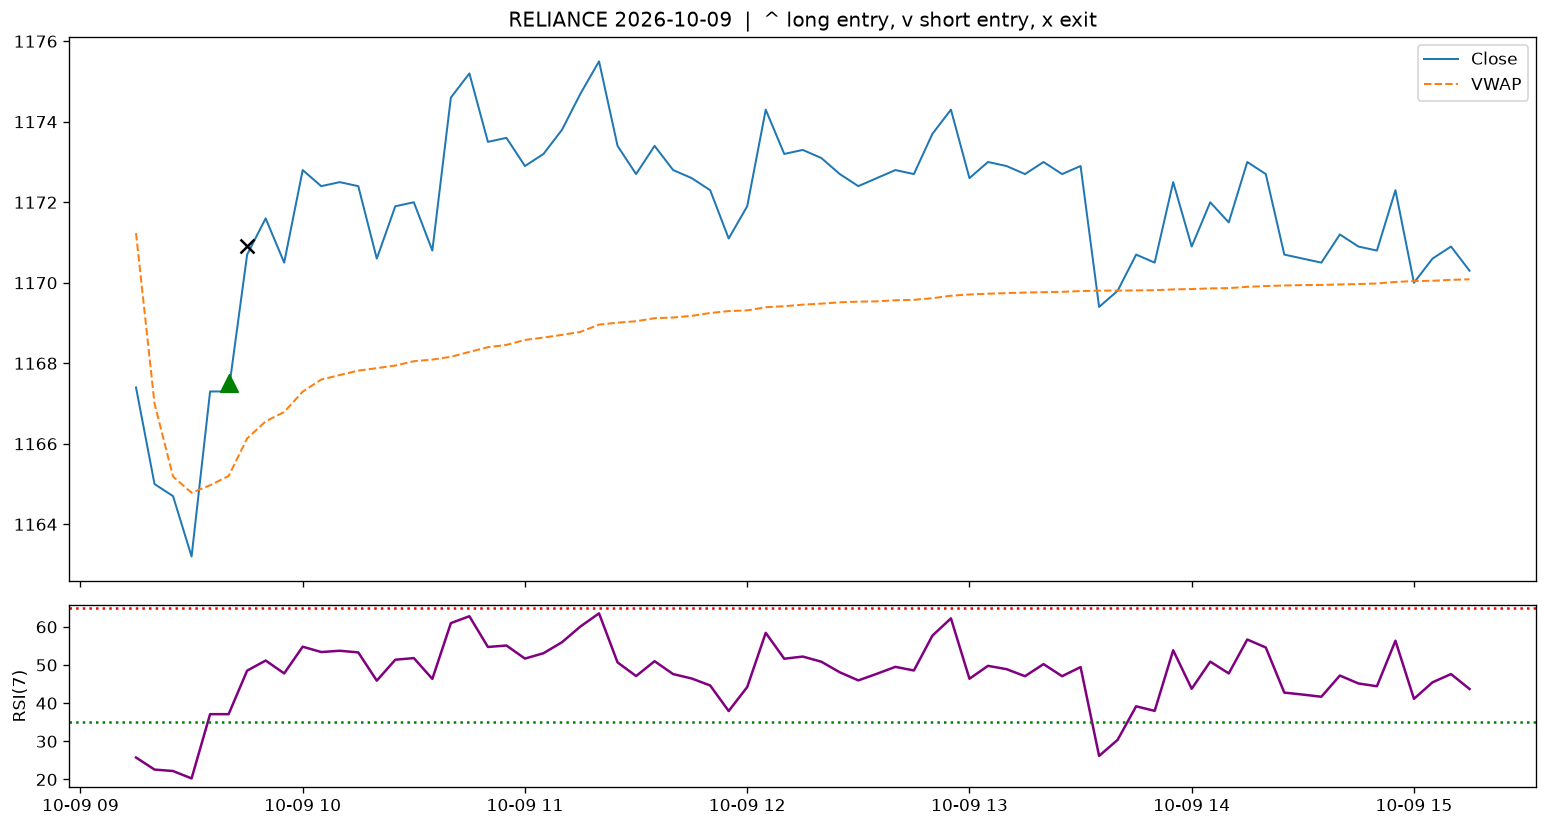

In [14]:
tr_test.to_csv(OUT_DIR / "trades_test.csv", index=False)
plot_equity(tr_test, OUT_DIR / "equity_curve_test.png")
if len(tr_test) > 0:
    s0 = tr_test.iloc[0]
    df0 = add_signals(add_indicators(raw[s0.symbol], bcfg["rsi_len"]), bcfg)
    plot_signals(df0, tr_test, s0.symbol, s0.date, OUT_DIR / "signals.png")
    print(tr_test.reason.value_counts())
else:
    print("No test trades generated to plot individual trade signals.")

## Notes
- Charts are saved in `output/` (`signals.png`, `equity_curve_test.png`) for slides and review.
- Out-of-sample metrics from step 12 reflect real-world performance on unseen current data.
- Backtests are not guarantees of live performance.